## 1. Imports and Configuration

In [1]:
# %pip install pydicom monai simpleitk --break-system-packages

In [2]:
# [IMPORTS]
import os
import numpy as np
import pandas as pd
import torch
import monai.transforms as mt
import pydicom
from pathlib import Path
import matplotlib.pyplot as plt
from scipy import stats

/opt/anaconda3/envs/ml_tutorial_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# [CONFIG]
KL_DIVERGENCE = '../../data/baseline/kl_divergence_beta_5.00e-05.csv'
CHECKPOINT_PATH = '../../models/checkpoints/beta_5.00e-05_best.pth'
MASK_PATH = '../../data/masks/rmask_ICV.nii'
IMAGES_ROOT     = '../../data/raw/ppmi_images'  # parent folder of PD/Cont/SWEDD
OUTPUT_DIR      = '../../results/augmentation/'
FIGURES_DIR     = '../../results/figures/'
os.makedirs(OUTPUT_DIR,  exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

N_SUBJECTS   = 100
RANDOM_STATE = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f"Device: {DEVICE}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"Images root: {IMAGES_ROOT}")

Device: cpu
Checkpoint: ../../models/checkpoints/beta_5.00e-05_best.pth
Images root: ../../data/raw/ppmi_images


## 2. Load Model

The β-VAE was trained by Professor Presotto and saved as beta_5.00e-05_best.pth. I copied selected_model.py from the training repository into our project to access the decoder and wrapper classes.

The encoder required a custom definition (CustomEncoder) because the checkpoint architecture differs slightly from the original BottleneckEncoder — specifically it has no channel reduction blocks. The encoder outputs a 512-dimensional vector which BottleneckAE splits into a 256-dimensional mean (mu) and log-variance. During inference only mu is used, giving a deterministic 256-dimensional latent representation per scan.

In [4]:
# Check the Checkpoint
import torch
checkpoint = torch.load(CHECKPOINT_PATH, map_location='cpu')
encoder_keys = [k for k in checkpoint.keys() if 'encoder' in k]
for k in encoder_keys:
    print(k, checkpoint[k].shape)

encoder.backbone.down1.0.block.conv.weight torch.Size([32, 1, 3, 3, 3])
encoder.backbone.down1.0.block.conv.bias torch.Size([32])
encoder.backbone.down1.0.block.bn.weight torch.Size([32])
encoder.backbone.down1.0.block.bn.bias torch.Size([32])
encoder.backbone.down1.0.block.bn.running_mean torch.Size([32])
encoder.backbone.down1.0.block.bn.running_var torch.Size([32])
encoder.backbone.down1.0.block.bn.num_batches_tracked torch.Size([])
encoder.backbone.down1.1.block.conv.weight torch.Size([32, 32, 3, 3, 3])
encoder.backbone.down1.1.block.conv.bias torch.Size([32])
encoder.backbone.down1.1.block.bn.weight torch.Size([32])
encoder.backbone.down1.1.block.bn.bias torch.Size([32])
encoder.backbone.down1.1.block.bn.running_mean torch.Size([32])
encoder.backbone.down1.1.block.bn.running_var torch.Size([32])
encoder.backbone.down1.1.block.bn.num_batches_tracked torch.Size([])
encoder.backbone.down2.0.block.conv.weight torch.Size([64, 32, 3, 3, 3])
encoder.backbone.down2.0.block.conv.bias torch

In [5]:
# Check the Encoder and Decoder
import sys
sys.path.append('../../models')
import inspect
from autoencoder.selected_model import BottleneckEncoder, ComplexBottleneckDeconvDecoder, BottleneckAE

# print(inspect.getsource(BottleneckEncoder))
print(inspect.getsource(BottleneckAE))

class BottleneckAE(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)



In [6]:
# Check the KL Divergence
import pandas as pd
df_kl = pd.read_csv(KL_DIVERGENCE)
print(f"Total dimensions: {len(df_kl)}")
print(df_kl.head())

Total dimensions: 256
  dimension   mean_kl
0  latent_0  0.013907
1  latent_1  0.004226
2  latent_2  0.122685
3  latent_3  0.096220
4  latent_4  0.013870


In [7]:
import torch.nn as nn

# [VAE-WRAPPER]
# ─────────────────────────────────────────────────────────────────
# BottleneckAE.forward passes the full encoder output directly to
# the decoder. Since our CustomEncoder returns (mu, log_var), we
# need a wrapper that:
# 1. Extracts only mu for the decoder (deterministic inference)
# 2. Exposes an encode() method that returns mu directly
# ─────────────────────────────────────────────────────────────────

class VAEWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def encode(self, x):
        out = self.model.encoder(x)
        mu = out[0] if isinstance(out, (tuple, list)) else out
        return mu  # shape (1, 256)

    def decode(self, z):
        # conv_transpose3d needs (B, C, D, H, W) — reshape flat latent to (B, 256, 1, 1, 1)
        if z.dim() == 2:
            z = z.unsqueeze(-1).unsqueeze(-1).unsqueeze(-1)  # → (1, 256, 1, 1, 1)
        return self.model.decoder(z)

    def forward(self, x):
        mu = self.encode(x)
        recon = self.decode(mu)
        return recon, mu

In [8]:
import sys
sys.path.append('../../models')
import importlib
import autoencoder.custom_encoder
importlib.reload(autoencoder.custom_encoder)
from autoencoder.custom_encoder import CustomEncoder
from autoencoder.selected_model import (
    BottleneckAE, ComplexBottleneckDeconvDecoder
)


def load_model(checkpoint_path, device='cpu'):
    encoder = CustomEncoder(initial_filters=32, latent_dim=256)
    decoder = ComplexBottleneckDeconvDecoder(latent_dim=256, target_shape=(64, 128, 128))
    base    = BottleneckAE(encoder, decoder)
    ckpt    = torch.load(checkpoint_path, map_location=device)
    base.load_state_dict(ckpt)
    base.eval()
    wrapped = VAEWrapper(base)
    wrapped.eval()
    # quick smoke test — catches tuple-to-decoder bug immediately
    dummy = torch.zeros(1, 1, 64, 128, 128, device=device)
    with torch.no_grad():
        recon, mu = wrapped(dummy)
    assert isinstance(recon, torch.Tensor), "decoder returned non-Tensor"
    assert isinstance(mu,    torch.Tensor), "encoder returned non-Tensor mu"
    print(f"Smoke test passed  recon {tuple(recon.shape)}  mu {tuple(mu.shape)}")
    return wrapped

model = load_model(CHECKPOINT_PATH, DEVICE)
vae = VAEWrapper(model)
vae.eval()
print("VAEWrapper ready")
print(f"Encode output dim: 256")

Smoke test passed  recon (1, 1, 64, 128, 128)  mu (1, 256)
VAEWrapper ready
Encode output dim: 256


## 3. Load Images and Select 100 Subjects

In [9]:
# [LOAD-IMAGES]

IMAGE_ROOT = Path('../../data/raw/ppmi_images')
GROUPS = {
    'PD':    IMAGE_ROOT / 'PPMI_Images_PD',
    'HC':    IMAGE_ROOT / 'PPMI_Images_Cont',
    'SWEDD': IMAGE_ROOT / 'PPMI_Images_SWEDD'
}

def find_dcm_files(root_dir, label):
    """Recursively find all .dcm files and extract PATNO."""
    records = []
    for dcm_path in Path(root_dir).rglob('*.dcm'):
        parts = dcm_path.parts
        # PATNO is the first subfolder under the group root
        relative = dcm_path.relative_to(root_dir)
        patno = relative.parts[0]
        records.append({
            'PATNO':    patno,
            'label':    label,
            'dcm_path': str(dcm_path)
        })
    return records

print("Scanning image folders...")
records = []
for label, folder in GROUPS.items():
    found = find_dcm_files(folder, label)
    print(f"  {label}: {len(found)} scans found")

    records.extend(found)
print("Records", records)
df_images = pd.DataFrame(records)
df_images = df_images.drop_duplicates(subset=['PATNO'], keep='first')

print(f"\nTotal unique subjects: {len(df_images)}")
print(df_images['label'].value_counts().to_string())
print(f"\nSample paths:")
print(df_images['dcm_path'].head(3).to_string())

# Select 100 subjects — stratified by group
np.random.seed(RANDOM_STATE)
n_per_group = {'PD': 70, 'HC': 20, 'SWEDD': 10}
selected = []
for label, n in n_per_group.items():
    group = df_images[df_images['label'] == label]
    n = min(n, len(group))
    selected.append(group.sample(n, random_state=RANDOM_STATE))

df_selected = pd.concat(selected).reset_index(drop=True)
print(f"\nSelected {len(df_selected)} subjects:")
print(df_selected['label'].value_counts().to_string())

Scanning image folders...
  PD: 1222 scans found
  HC: 378 scans found
  SWEDD: 136 scans found
Records [{'PATNO': '172854', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/172854/Reconstructed_DaTSCAN/2022-09-30_12_51_28.0/I1632125/PPMI_172854_NM_Reconstructed_DaTSCAN_Br_20221019121702557_1_S1167989_I1632125.dcm'}, {'PATNO': '174996', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/174996/Reconstructed_DaTSCAN/2023-04-10_12_01_34.0/I1697979/PPMI_174996_NM_Reconstructed_DaTSCAN_Br_20230508142952090_1_S1220249_I1697979.dcm'}, {'PATNO': '142631', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/142631/Reconstructed_DaTSCAN/2022-02-15_14_29_07.0/I1562666/PPMI_142631_NM_Reconstructed_DaTSCAN_Br_20220330192012701_1_S1118837_I1562666.dcm'}, {'PATNO': '137450', 'label': 'PD', 'dcm_path': '../../data/raw/ppmi_images/PPMI_Images_PD/137450/Reconstructed_DaTSCAN/2022-09-13_12_53_28.0/I1644916/PPMI_137450_NM_Reconstructed_DaTSCAN_Br_

## 4. Load DICOM

In [10]:
# [NORMALISATION]
import nibabel as nib
import torch

_mask_img = nib.load(MASK_PATH)
# Apply the SAME permutation as training
_mask_tensor = torch.from_numpy(_mask_img.get_fdata()).float()
_mask_tensor = _mask_tensor.permute(2, 1, 0)  # (x,y,z) → (z,y,x)
_mask_tensor = _mask_tensor.flip(1).flip(2)           # flip y axis
_mask = _mask_tensor.numpy().astype(bool)     # back to numpy bool (91,109,91)

def normalize_volume(vol: np.ndarray) -> np.ndarray:
    # Apply same permutation to the volume before masking
    vol_t = torch.from_numpy(vol).float()
    vol_t = vol_t.permute(2, 1, 0)
    vol_t = vol_t.flip(1)
    vol = vol_t.numpy()
    
    vol = vol - vol.min()
    vol = vol * _mask
    vol = vol / np.mean(vol[_mask])
    return vol

In [11]:
# [LOAD-DICOM]

import torch
import numpy as np
import pydicom
from monai.transforms import Compose, SpatialCropd, SpatialPadd
import SimpleITK as sitk


def load_dicom_series(dcm_path):
    dcm_dir = str(Path(dcm_path).parent)
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(dcm_dir)
    
    if len(dicom_names) == 0:
        img = sitk.ReadImage(dcm_path)
    else:
        reader.SetFileNames(dicom_names)
        img = reader.Execute()
    
    vol = sitk.GetArrayFromImage(img).astype(np.float32)
    
    # Squeeze out any extra dimensions
    vol = np.squeeze(vol)
    print(f"load_dicom_series shape after squeeze: {vol.shape}")
    return vol

    
def load_and_transform(dcm_path):
    """Load DICOM, normalise, apply val_transforms, return tensor ready for model."""
    # dcm = pydicom.dcmread(dcm_path)
    vol = load_dicom_series(dcm_path) 
    # vol = dcm.pixel_array.astype(np.float32)  # shape (91, 109, 91)

    vol = normalize_volume(vol)               # ← training-time normalisation

    vol = vol[np.newaxis, ...]                # add channel dim → (1, 91, 109, 91)
    data = {'image': vol}

    val_transforms = Compose([
        SpatialCropd(
            keys=['image'],
            roi_slices=[slice(9, 73), slice(None), slice(None)]
        ),
        SpatialPadd(
            keys=['image'],
            spatial_size=[64, 128, 128],
            mode='constant',
            constant_values=0
        ),
    ])

    data = val_transforms(data)
    tensor = torch.tensor(np.array(data['image'])).float().unsqueeze(0).to(DEVICE)
    return tensor


# Test on one subject
test_path = df_selected.iloc[0]['dcm_path']
print(f"Loading: {test_path}")

scan = load_and_transform(test_path)
print(f"Transformed shape: {scan.shape}")

with torch.no_grad():
    mu = model.encode(scan)
print(f"Latent mu shape: {mu.shape}")
print(f"Sample values: {mu[0, :5].cpu().numpy()}")

Loading: ../../data/raw/ppmi_images/PPMI_Images_PD/171091/Reconstructed_DaTSCAN/2022-09-29_14_53_32.0/I1632123/PPMI_171091_NM_Reconstructed_DaTSCAN_Br_20221019121629093_1_S1167985_I1632123.dcm
load_dicom_series shape after squeeze: (91, 109, 91)
Transformed shape: torch.Size([1, 1, 64, 128, 128])
Latent mu shape: torch.Size([1, 256])
Sample values: [-0.33600643 -0.5419624  -1.5634694   0.5125021  -0.05634017]


/var/folders/x_/6yv4myms0vgby9kqty8ns9wh0000gr/T/ipykernel_59734/3586108474.py:54: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  tensor = torch.tensor(np.array(data['image'])).float().unsqueeze(0).to(DEVICE)


## 5. Augmentations

In [12]:
# [AUGMENTATIONS]
    # Define deterministic augmentations to apply one at a time.
    # Each returns a transformed volume (D, H, W) numpy array.

from scipy.ndimage import shift, gaussian_filter
from skimage.transform import resize

def aug_shift_left(vol):
    return shift(vol, shift=[0, 0, 2], mode='constant', cval=0)

def aug_shift_right(vol):
    return shift(vol, shift=[0, 0, -2], mode='constant', cval=0)

def aug_intensity_up(vol):
    return vol * 1.1

def aug_intensity_down(vol):
    return vol * 0.9

def aug_flip_lr(vol):
    return np.flip(vol, axis=2).copy()

def aug_gaussian_noise(vol, std=0.3):
    noise = np.random.default_rng(42).normal(0, std, vol.shape).astype(np.float32)
    return vol + noise

def aug_gaussian_smooth(vol, sigma=1.0):
    return gaussian_filter(vol, sigma=sigma).astype(np.float32)

AUGMENTATIONS = {
    'shift_left':       aug_shift_left,
    'shift_right':      aug_shift_right,
    'intensity_up':     aug_intensity_up,
    'intensity_down':   aug_intensity_down,
    'flip_lr':          aug_flip_lr,
    'gaussian_noise':   aug_gaussian_noise,
    'gaussian_smooth':  aug_gaussian_smooth,
}

print(f"Augmentations defined: {list(AUGMENTATIONS.keys())}")

Augmentations defined: ['shift_left', 'shift_right', 'intensity_up', 'intensity_down', 'flip_lr', 'gaussian_noise', 'gaussian_smooth']


In [13]:
# [AUGMENTATION-LOOP]
    # For each subject and each augmentation:
    #   1. Load original scan → extract mu_original
    #   2. Apply augmentation → extract mu_augmented
    #   3. Compute delta = mu_augmented - mu_original


from monai.transforms import Compose, SpatialCropd, SpatialPadd
from tqdm import tqdm

def vol_to_tensor(vol):
    """Apply normalisation + val_transforms to a (91,109,91) array."""
    vol = normalize_volume(vol)               # ← training-time normalisation
    # print("val_to_tensor", vol.shape)
    data = {'image': vol[np.newaxis, ...]}
    val_transforms = Compose([
        SpatialCropd(keys=['image'], roi_slices=[slice(9, 73), slice(None), slice(None)]),
        SpatialPadd(keys=['image'], spatial_size=[64, 128, 128], mode='constant', constant_values=0),
    ])
    data = val_transforms(data)
    tensor = torch.from_numpy(np.array(data['image'], dtype=np.float32)).unsqueeze(0).to(DEVICE)
    return tensor

def extract_mu(vol):
    tensor = vol_to_tensor(vol)
    with torch.no_grad():
        mu = model.encode(tensor)
    return mu.cpu().numpy()[0]  # (256,)


results = []

print(f"Running augmentation experiment on {len(df_selected)} subjects...")

for idx, row in tqdm(df_selected.iterrows(), total=len(df_selected)):
    patno    = row['PATNO']
    label    = row['label']
    dcm_path = row['dcm_path']

    try:
        #
        vol = load_dicom_series(dcm_path)   # (91, 109, 91) float32, raw

        # Original latent (normalize_volume + transforms applied inside extract_mu)
        mu_orig = extract_mu(vol)

        # Augmented latents
        for aug_name, aug_fn in AUGMENTATIONS.items():
            vol_aug = aug_fn(vol)           # augment raw volume
            mu_aug  = extract_mu(vol_aug)   # normalize + encode
            delta   = mu_aug - mu_orig

            for dim_idx in range(len(delta)):
                results.append({
                    'PATNO':   patno,
                    'label':   label,
                    'aug':     aug_name,
                    'dim':     f'latent_{dim_idx}',
                    'delta':   delta[dim_idx],
                    'mu_orig': mu_orig[dim_idx],
                    'mu_aug':  mu_aug[dim_idx],
                })

    except Exception as e:
        print(f"  Skipping {patno}: {e}")

df_delta = pd.DataFrame(results)
print(f"\nDone. Total rows: {len(df_delta)}")
print(df_delta.head())

# Save
os.makedirs('../../results/augmentation', exist_ok=True)
df_delta.to_csv('../../results/augmentation/delta_per_augmentation.csv', index=False)
print("Saved to results/augmentation/delta_per_augmentation.csv")

Running augmentation experiment on 100 subjects...


  0%|          | 0/100 [00:00<?, ?it/s]

load_dicom_series shape after squeeze: (91, 109, 91)


/var/folders/x_/6yv4myms0vgby9kqty8ns9wh0000gr/T/ipykernel_59734/2257085613.py:21: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  tensor = torch.from_numpy(np.array(data['image'], dtype=np.float32)).unsqueeze(0).to(DEVICE)
  1%|          | 1/100 [00:02<03:25,  2.08s/it]

load_dicom_series shape after squeeze: (91, 109, 91)


...

load_dicom_series shape after squeeze: (91, 109, 91)


 99%|█████████▉| 99/100 [03:05<00:01,  1.84s/it]

load_dicom_series shape after squeeze: (91, 109, 91)


100%|██████████| 100/100 [03:07<00:00,  1.87s/it]



Done. Total rows: 177408
    PATNO label         aug       dim     delta   mu_orig    mu_aug
0  171091    PD  shift_left  latent_0 -0.017241 -0.336006 -0.353247
1  171091    PD  shift_left  latent_1 -0.022767 -0.541962 -0.564729
2  171091    PD  shift_left  latent_2  0.072156 -1.563469 -1.491314
3  171091    PD  shift_left  latent_3 -0.121795  0.512502  0.390707
4  171091    PD  shift_left  latent_4 -0.002928 -0.056340 -0.059268
Saved to results/augmentation/delta_per_augmentation.csv


In [14]:
# [DELTA-ANALYSIS]
    # For each augmentation, compute mean absolute delta per dimension.
    # High mean |delta| = dimension is sensitive to that augmentation.

import matplotlib.pyplot as plt
import seaborn as sns

# Mean absolute delta per augmentation per dimension
df_mean = (df_delta
           .groupby(['aug', 'dim'])['delta']
           .apply(lambda x: np.abs(x).mean())
           .reset_index()
           .rename(columns={'delta': 'mean_abs_delta'})
           )

# Extract dim index for sorting
df_mean['dim_idx'] = df_mean['dim'].str.replace('latent_', '').astype(int)
df_mean = df_mean.sort_values(['aug', 'dim_idx'])

# Save summary
df_mean.to_csv('../../results/augmentation/mean_abs_delta_per_dim.csv', index=False)

# Top 10 most sensitive dimensions per augmentation
print("Top 10 most sensitive dimensions per augmentation:\n")
for aug_name in AUGMENTATIONS.keys():
    top = (df_mean[df_mean['aug'] == aug_name]
           .nlargest(10, 'mean_abs_delta')[['dim', 'mean_abs_delta']])
    print(f"--- {aug_name} ---")
    print(top.to_string(index=False))
    print()

Top 10 most sensitive dimensions per augmentation:

--- shift_left ---
       dim  mean_abs_delta
 latent_51        0.354627
latent_173        0.213069
latent_232        0.202828
latent_235        0.186578
latent_228        0.184735
 latent_29        0.155426
 latent_83        0.152790
latent_171        0.144056
latent_120        0.141240
 latent_66        0.131642

--- shift_right ---
       dim  mean_abs_delta
 latent_51        0.385133
latent_173        0.198453
latent_232        0.189110
latent_228        0.160883
latent_171        0.156031
latent_235        0.154495
latent_120        0.149887
 latent_29        0.149266
latent_222        0.141484
latent_106        0.135295

--- intensity_up ---
       dim  mean_abs_delta
latent_150    5.067915e-07
latent_228    4.591990e-07
latent_132    3.843891e-07
  latent_7    3.304104e-07
 latent_66    3.176000e-07
latent_141    3.095412e-07
latent_222    2.859350e-07
latent_218    2.688291e-07
 latent_15    2.666624e-07
 latent_70    2.647237

In [31]:
# [TOP-DIM ANALYSIS]
# Cross-reference sensitive dims with KL divergence + PD/HC separation

# ── Top sensitive dims (across all augs combined) ──────────────────────────
top_sensitive = (df_mean.groupby('dim_idx')['mean_abs_delta']
                 .mean()
                 .nlargest(20)
                 .reset_index()
                 .rename(columns={'mean_abs_delta': 'avg_sensitivity'}))

print("Top 20 most sensitive dimensions (averaged across augmentations):")
print(top_sensitive.to_string(index=False))

# ── PD vs HC separation for top sensitive dims ─────────────────────────────
top_dim_indices = top_sensitive['dim_idx'].tolist()

# Get mu_orig for each subject (one row per subject per dim)
df_orig = (df_delta[df_delta['aug'] == 'shift_left']  # any aug, mu_orig is the same
           [['PATNO', 'label', 'dim', 'mu_orig']]
           .copy())
df_orig['dim_idx'] = df_orig['dim'].str.replace('latent_', '').astype(int)
df_orig = df_orig[df_orig['dim_idx'].isin(top_dim_indices)]

# Cohen's d for PD vs HC per dimension
from scipy import stats

separation = []
for dim_idx in top_dim_indices:
    vals = df_orig[df_orig['dim_idx'] == dim_idx]
    pd_vals = vals[vals['label'] == 'PD']['mu_orig'].dropna().values
    hc_vals = vals[vals['label'] == 'HC']['mu_orig'].dropna().values
    
    if len(pd_vals) > 5 and len(hc_vals) > 5:
        t, p = stats.ttest_ind(pd_vals, hc_vals)
        pooled_std = np.sqrt((pd_vals.std()**2 + hc_vals.std()**2) / 2)
        cohens_d = (pd_vals.mean() - hc_vals.mean()) / (pooled_std + 1e-8)
        separation.append({
            'dim_idx': dim_idx,
            'cohens_d': cohens_d,
            'p_value': p,
            'pd_mean': pd_vals.mean(),
            'hc_mean': hc_vals.mean(),
        })
    print(f"dim {dim_idx}: pd_std={pd_vals.std():.4f}, hc_std={hc_vals.std():.4f}, pooled={np.sqrt((pd_vals.std()**2 + hc_vals.std()**2) / 2):.4f}")    

df_sep = pd.DataFrame(separation).sort_values('cohens_d', key=abs, ascending=False)
print("\nPD vs HC separation for top sensitive dims:")
print(df_sep.to_string(index=False))

print("-" * 50)
print("Separation Table")
df_sep = pd.DataFrame(separation).sort_values('cohens_d', key=abs, ascending=False)
print(df_sep.to_string(index=False))


Top 20 most sensitive dimensions (averaged across augmentations):
 dim_idx  avg_sensitivity
      51         0.172441
     173         0.103019
     232         0.100887
     228         0.085963
      83         0.084429
     235         0.079871
     222         0.079254
     171         0.078391
      14         0.073934
      66         0.072803
      29         0.068781
     106         0.068667
     162         0.066650
     120         0.066615
     225         0.065140
     192         0.063784
     214         0.062855
     197         0.062252
       2         0.062135
      85         0.060609
dim 51: pd_std=0.5045, hc_std=0.3348, pooled=0.4282
dim 173: pd_std=0.4735, hc_std=0.4404, pooled=0.4573
dim 232: pd_std=0.6496, hc_std=0.5803, pooled=0.6159
dim 228: pd_std=0.4526, hc_std=0.3354, pooled=0.3984
dim 83: pd_std=0.4829, hc_std=0.4106, pooled=0.4483
dim 235: pd_std=0.3555, hc_std=0.3066, pooled=0.3319
dim 222: pd_std=0.8632, hc_std=0.7368, pooled=0.8025
dim 171: pd_std=0.7

## 6. Visualization

Top 10 most sensitive dimensions per augmentation:

--- shift_left ---
       dim  mean_abs_delta
 latent_51        0.354627
latent_173        0.213069
latent_232        0.202828
latent_235        0.186578
latent_228        0.184735
 latent_29        0.155426
 latent_83        0.152790
latent_171        0.144056
latent_120        0.141240
 latent_66        0.131642

--- shift_right ---
       dim  mean_abs_delta
 latent_51        0.385133
latent_173        0.198453
latent_232        0.189110
latent_228        0.160883
latent_171        0.156031
latent_235        0.154495
latent_120        0.149887
 latent_29        0.149266
latent_222        0.141484
latent_106        0.135295

--- intensity_up ---
       dim  mean_abs_delta
latent_150    5.067915e-07
latent_228    4.591990e-07
latent_132    3.843891e-07
  latent_7    3.304104e-07
 latent_66    3.176000e-07
latent_141    3.095412e-07
latent_222    2.859350e-07
latent_218    2.688291e-07
 latent_15    2.666624e-07
 latent_70    2.647237

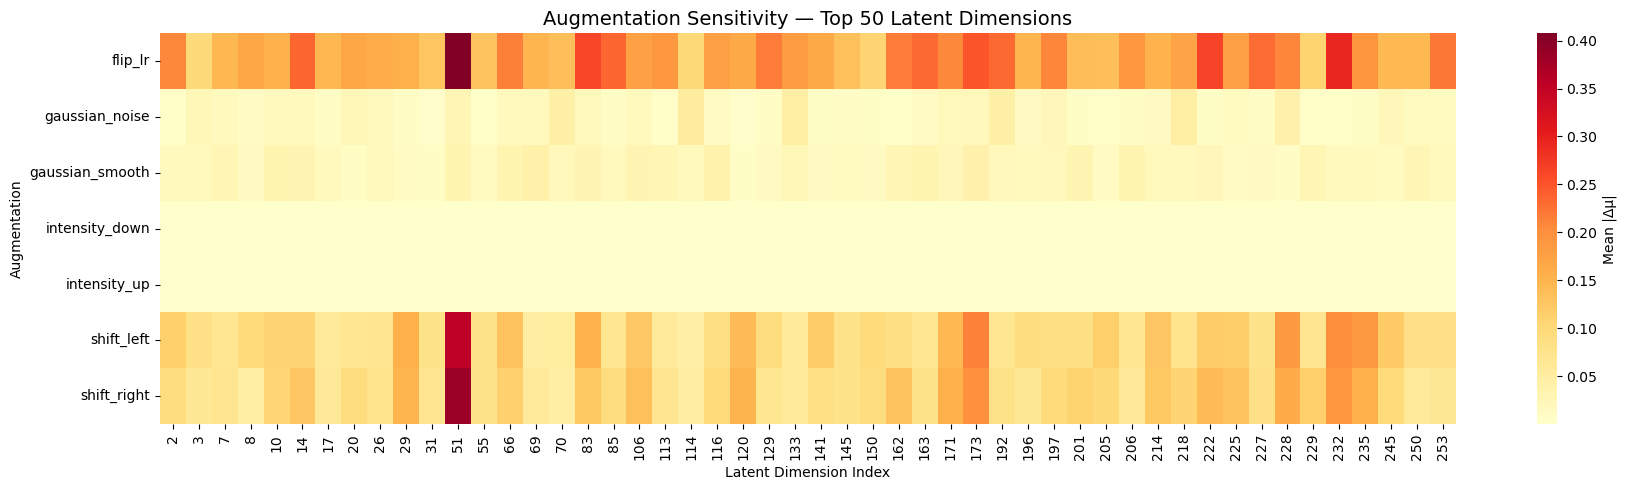

Saved heatmap.


In [32]:
# [SENSITIVITY-HEATMAP]
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ── 1. Mean |delta| per aug × dim ──────────────────────────────────────────
df_mean = (df_delta
           .groupby(['aug', 'dim'])['delta']
           .apply(lambda x: np.abs(x).mean())
           .reset_index()
           .rename(columns={'delta': 'mean_abs_delta'}))

df_mean['dim_idx'] = df_mean['dim'].str.replace('latent_', '').astype(int)
df_mean = df_mean.sort_values(['aug', 'dim_idx'])

# ── 2. Top 10 per augmentation ─────────────────────────────────────────────
print("Top 10 most sensitive dimensions per augmentation:\n")
for aug_name in AUGMENTATIONS.keys():
    top = (df_mean[df_mean['aug'] == aug_name]
           .nlargest(10, 'mean_abs_delta')[['dim', 'mean_abs_delta']])
    print(f"--- {aug_name} ---")
    print(top.to_string(index=False))
    print()

# ── 3. Pivot for heatmap (aug × dim) ──────────────────────────────────────
pivot = df_mean.pivot(index='aug', columns='dim_idx', values='mean_abs_delta')

# ── 4. Plot: show only top 50 most sensitive dims (across all augs) ────────
top_dims = df_mean.groupby('dim_idx')['mean_abs_delta'].mean().nlargest(50).index
pivot_top = pivot[top_dims.sort_values()]

fig, ax = plt.subplots(figsize=(18, 5))
sns.heatmap(pivot_top, ax=ax, cmap='YlOrRd', linewidths=0,
            cbar_kws={'label': 'Mean |Δμ|'})
ax.set_title('Augmentation Sensitivity — Top 50 Latent Dimensions', fontsize=14)
ax.set_xlabel('Latent Dimension Index')
ax.set_ylabel('Augmentation')
plt.tight_layout()
plt.savefig('../../results/augmentation/sensitivity_heatmap.png', dpi=150)
plt.show()
print("Saved heatmap.")

# ── 5. Save summary ────────────────────────────────────────────────────────
df_mean.to_csv('../../results/augmentation/mean_abs_delta_per_dim.csv', index=False)

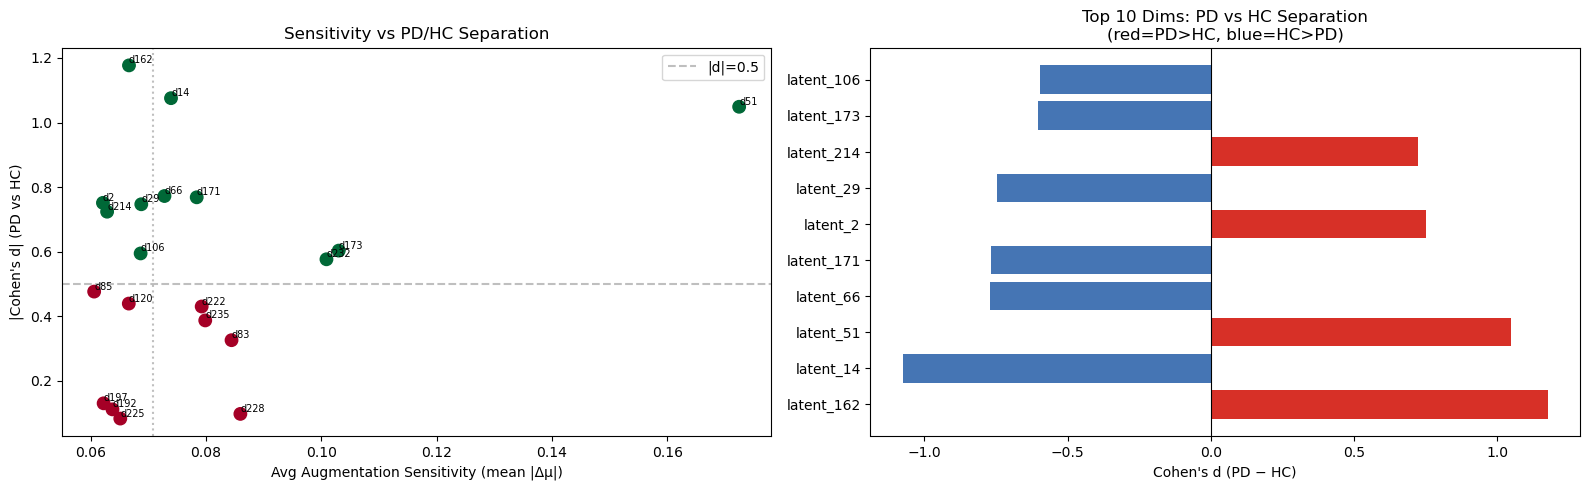

In [33]:
# [COMBINED PLOT: sensitivity vs PD/HC separation]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: scatter — sensitivity vs |Cohen's d|
ax = axes[0]
merged = top_sensitive.merge(df_sep, on='dim_idx')
ax.scatter(merged['avg_sensitivity'], merged['cohens_d'].abs(),
           c=merged['p_value'] < 0.05, cmap='RdYlGn', s=80)
for _, r in merged.iterrows():
    ax.annotate(f"d{int(r['dim_idx'])}", (r['avg_sensitivity'], abs(r['cohens_d'])),
                fontsize=7, ha='left', va='bottom')
ax.set_xlabel('Avg Augmentation Sensitivity (mean |Δμ|)')
ax.set_ylabel("|Cohen's d| (PD vs HC)")
ax.set_title('Sensitivity vs PD/HC Separation')
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.5, label='|d|=0.5')
ax.axvline(merged['avg_sensitivity'].median(), color='gray', linestyle=':', alpha=0.5)
ax.legend()

# Right: bar — top 10 dims by |Cohen's d|, coloured by direction
ax = axes[1]
top10_sep = df_sep.nlargest(10, 'cohens_d', keep='all').head(10)
top10_sep = df_sep.reindex(df_sep['cohens_d'].abs().nlargest(10).index)
colors = ['#d73027' if d > 0 else '#4575b4' for d in top10_sep['cohens_d']]
ax.barh(top10_sep['dim_idx'].astype(str).apply(lambda x: f'latent_{x}'),
        top10_sep['cohens_d'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel("Cohen's d (PD − HC)")
ax.set_title("Top 10 Dims: PD vs HC Separation\n(red=PD>HC, blue=HC>PD)")

plt.tight_layout()
plt.savefig('../../results/augmentation/sensitivity_vs_separation.png', dpi=150)
plt.show()

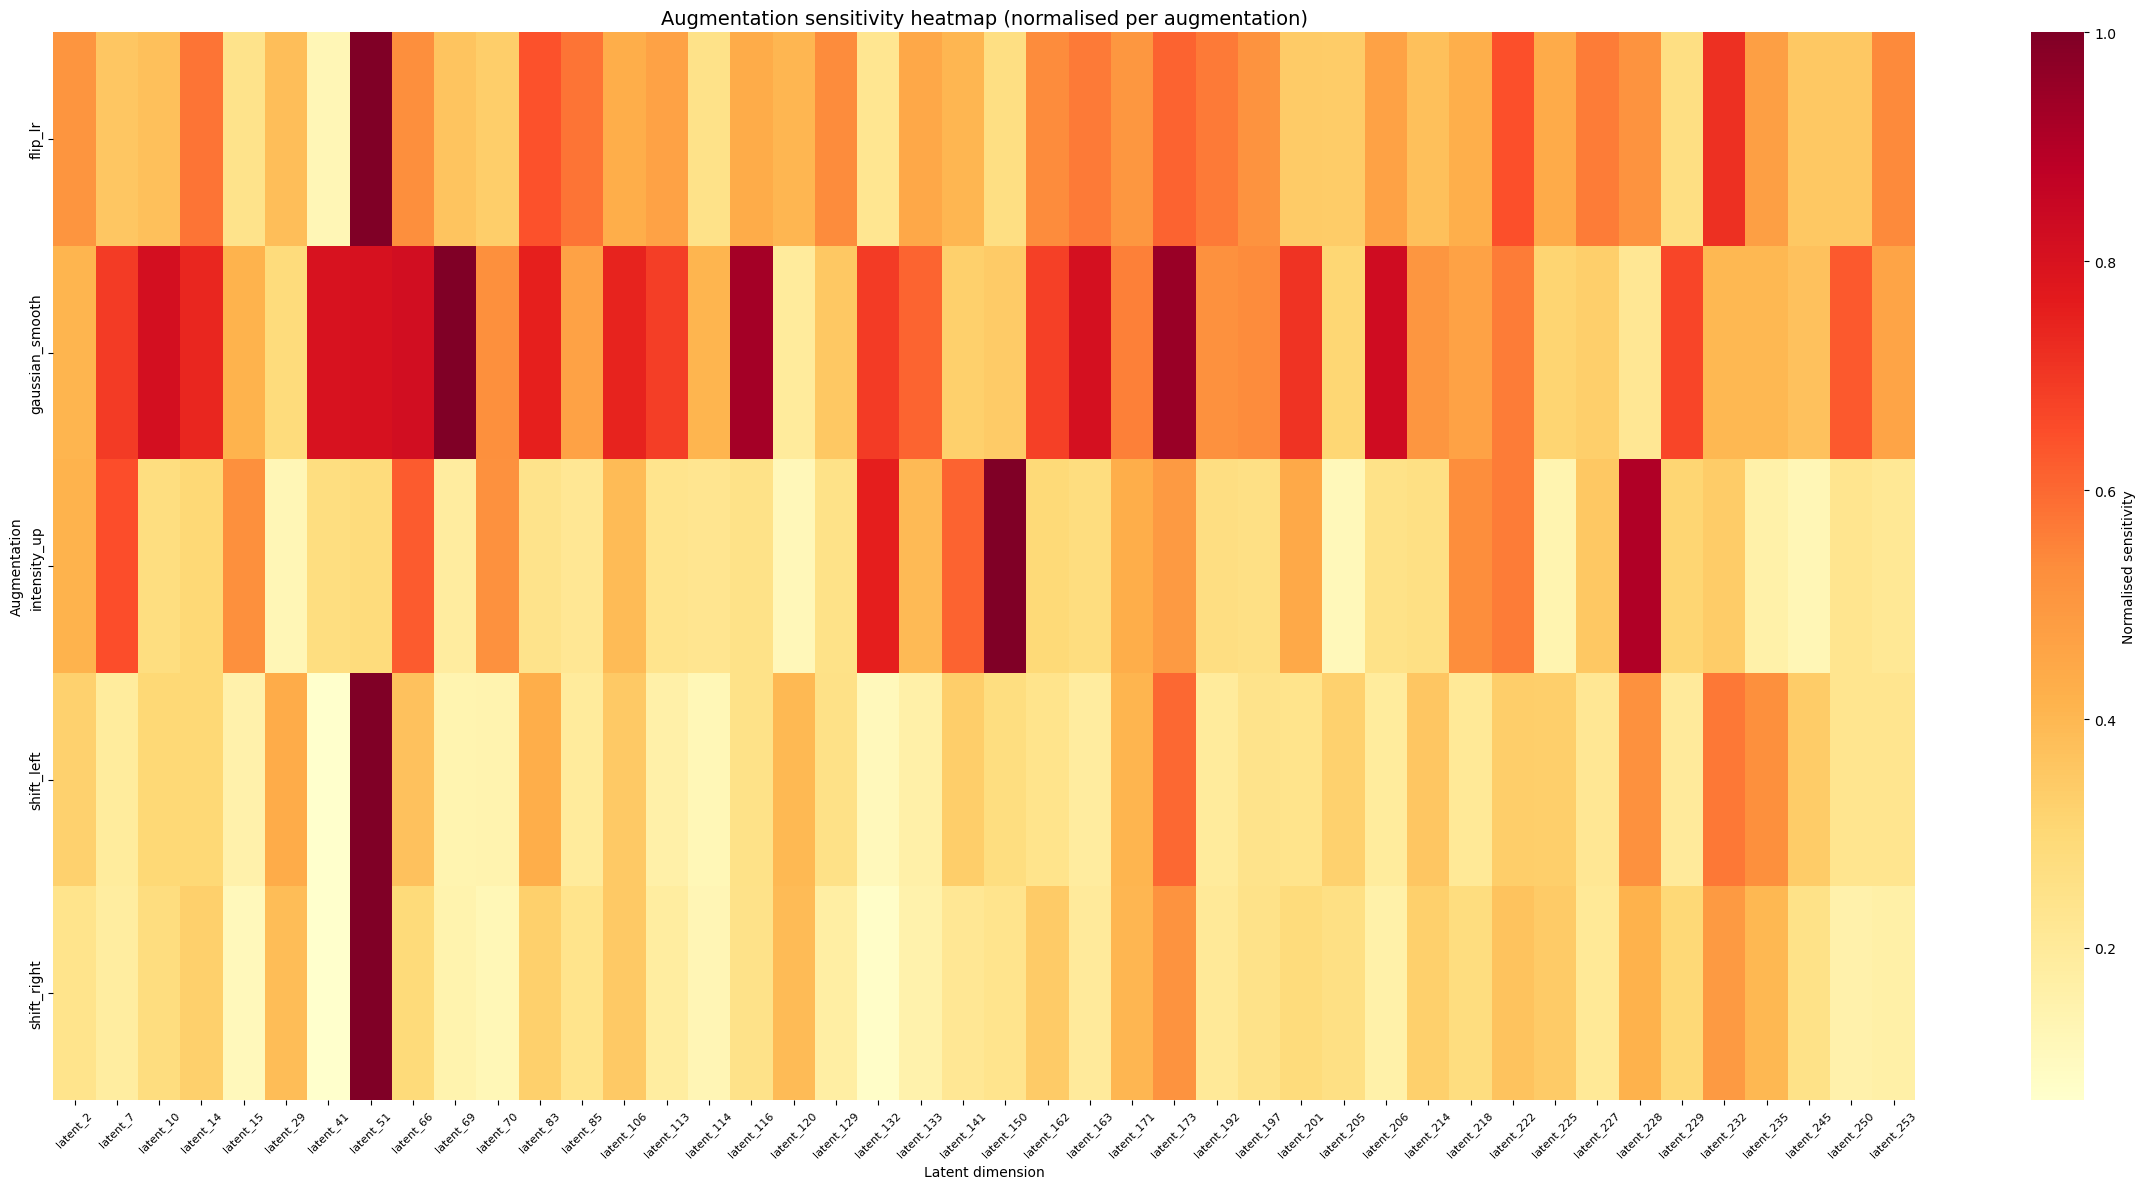

Saved.


In [16]:
# [VISUALISATION]
# Heatmap: augmentation × top sensitive dimensions

# Collect top 20 dims across all augmentations (excluding gaussian_noise)
augs_to_plot = ['shift_left', 'shift_right', 'intensity_up', 'flip_lr', 'gaussian_smooth']

top_dims = set()
for aug_name in augs_to_plot:
    top = (df_mean[df_mean['aug'] == aug_name]
           .nlargest(20, 'mean_abs_delta')['dim'].tolist())
    top_dims.update(top)

# Always include key dims
top_dims.update(['latent_132', 'latent_173', 'latent_114', 'latent_218'])
top_dims = sorted(top_dims, key=lambda x: int(x.replace('latent_', '')))

# Pivot table
df_heatmap = (df_mean[df_mean['aug'].isin(augs_to_plot)]
              .pivot(index='aug', columns='dim', values='mean_abs_delta')
              [top_dims])

# Normalise per augmentation row (0-1)
df_norm = df_heatmap.div(df_heatmap.max(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(24, 12))
sns.heatmap(df_norm, cmap='YlOrRd', ax=ax, cbar_kws={'label': 'Normalised sensitivity'})
ax.set_title('Augmentation sensitivity heatmap (normalised per augmentation)', fontsize=14)
ax.set_xlabel('Latent dimension')
ax.set_ylabel('Augmentation')
plt.xticks(rotation=45, fontsize=8)
plt.tight_layout()
plt.savefig('../../results/figures/augmentation_sensitivity_heatmap.png', dpi=150)
plt.show()
print("Saved.")

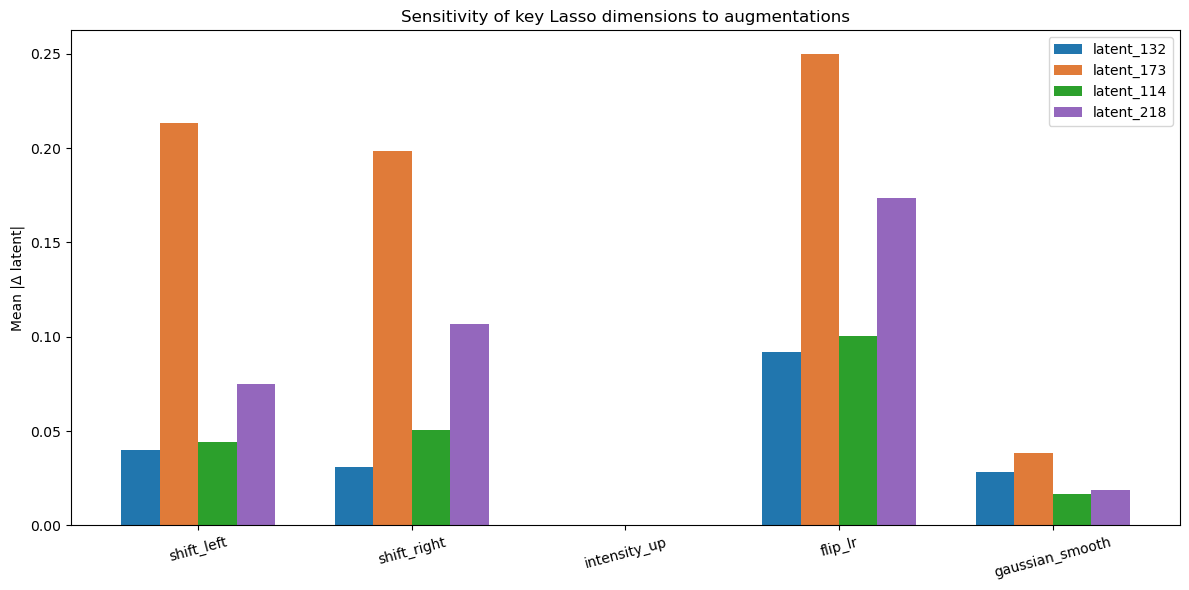

Saved.


In [17]:
# [KEY-DIMS-PLOT]
# ─────────────────────────────────────────────────────────────────
# Bar plot: sensitivity of key Lasso dimensions per augmentation
# ─────────────────────────────────────────────────────────────────

key_dims = ['latent_132', 'latent_173', 'latent_114', 'latent_218']
augs_to_plot = ['shift_left', 'shift_right', 'intensity_up', 'flip_lr', 'gaussian_smooth']

df_key = df_mean[
    df_mean['dim'].isin(key_dims) &
    df_mean['aug'].isin(augs_to_plot)
].copy()

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(augs_to_plot))
width = 0.18
colors = ['#2176ae', '#e07b39', '#2ca02c', '#9467bd']

for i, dim in enumerate(key_dims):
    vals = [df_key[(df_key['aug'] == aug) & (df_key['dim'] == dim)]['mean_abs_delta'].values[0]
            for aug in augs_to_plot]
    ax.bar(x + i * width, vals, width, label=dim, color=colors[i])

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(augs_to_plot, rotation=15)
ax.set_ylabel('Mean |Δ latent|')
ax.set_title('Sensitivity of key Lasso dimensions to augmentations')
ax.legend()
plt.tight_layout()
plt.savefig('../../results/figures/augmentation_top_dims.png', dpi=150)
plt.show()
print("Saved.")

## 7. Sanity Check

In [18]:
# [RECONSTRUCTION-SANITY-CHECK]

# ICV normalisation (same as training) 
import nibabel as nib
import torch

_mask_img = nib.load(MASK_PATH)
# Apply the SAME permutation as training
_mask_tensor = torch.from_numpy(_mask_img.get_fdata()).float()
_mask_tensor = _mask_tensor.permute(2, 1, 0)  # (x,y,z) → (z,y,x)
_mask_tensor = _mask_tensor.flip(1)           # flip y axis
_mask = _mask_tensor.numpy().astype(bool)     # back to numpy bool (91,109,91)

def normalize_volume(vol: np.ndarray) -> np.ndarray:
    # Apply same permutation to the volume before masking
    vol_t = torch.from_numpy(vol).float()
    vol_t = vol_t.permute(2, 1, 0)
    vol_t = vol_t.flip(2)
    vol = vol_t.numpy()
    
    vol = vol - vol.min()
    vol = vol * _mask
    vol = vol / np.mean(vol[_mask])
    return vol

_val_tf = Compose([
    SpatialCropd(keys=['image'], roi_slices=[slice(9, 73), slice(None), slice(None)]),
    SpatialPadd(keys=['image'], spatial_size=[64, 128, 128], mode='constant', constant_values=0),
])

def load_and_transform(dcm_path):
    vol = pydicom.dcmread(str(dcm_path)).pixel_array.astype(np.float32)
    vol = normalize_volume(vol)
    d = _val_tf({'image': vol[np.newaxis, ...]})
    return torch.tensor(np.array(d['image'])).float().unsqueeze(0).to(DEVICE)

# pick 3 PD + 3 HC subjects
GROUPS_RC = {
    'PD': Path(IMAGES_ROOT) / 'PPMI_Images_PD',
    'HC': Path(IMAGES_ROOT) / 'PPMI_Images_Cont',
}

def first_dcm(root):
    for p in sorted(Path(root).rglob('*.dcm')):
        return p

subjects_rc = []
for label, folder in GROUPS_RC.items():
    for subj_dir in sorted(folder.iterdir())[:3]:
        dcm = first_dcm(subj_dir)
        if dcm:
            subjects_rc.append({'label': label, 'dcm': dcm, 'name': subj_dir.name})

print(f"Subjects selected: {len(subjects_rc)}")

# encode → decode
results_rc = []
with torch.no_grad():
    for s in subjects_rc:
        t = load_and_transform(s['dcm'])
        recon, mu = model(t)          # model is the VAEWrapper already loaded
        orig_np  = t[0, 0].cpu().numpy()
        recon_np = recon[0, 0].cpu().numpy()
        mse = np.mean((orig_np - recon_np) ** 2)
        print(f"  {s['label']}  {s['name'][:16]:16s}  MSE={mse:.4f}  "
              f"μ range [{mu.min():.2f}, {mu.max():.2f}]")
        results_rc.append({**s, 'orig': orig_np, 'recon': recon_np, 'mse': mse})

Subjects selected: 4


/var/folders/x_/6yv4myms0vgby9kqty8ns9wh0000gr/T/ipykernel_59734/1042498364.py:35: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return torch.tensor(np.array(d['image'])).float().unsqueeze(0).to(DEVICE)


  PD  100001            MSE=0.0136  μ range [-2.23, 3.56]
  PD  100002            MSE=0.0104  μ range [-2.25, 2.48]
  HC  100004            MSE=0.0127  μ range [-2.46, 3.10]
  HC  100890            MSE=0.0208  μ range [-3.43, 4.19]


Saved → results/figures/reconstruction_sanity_check_v2.png


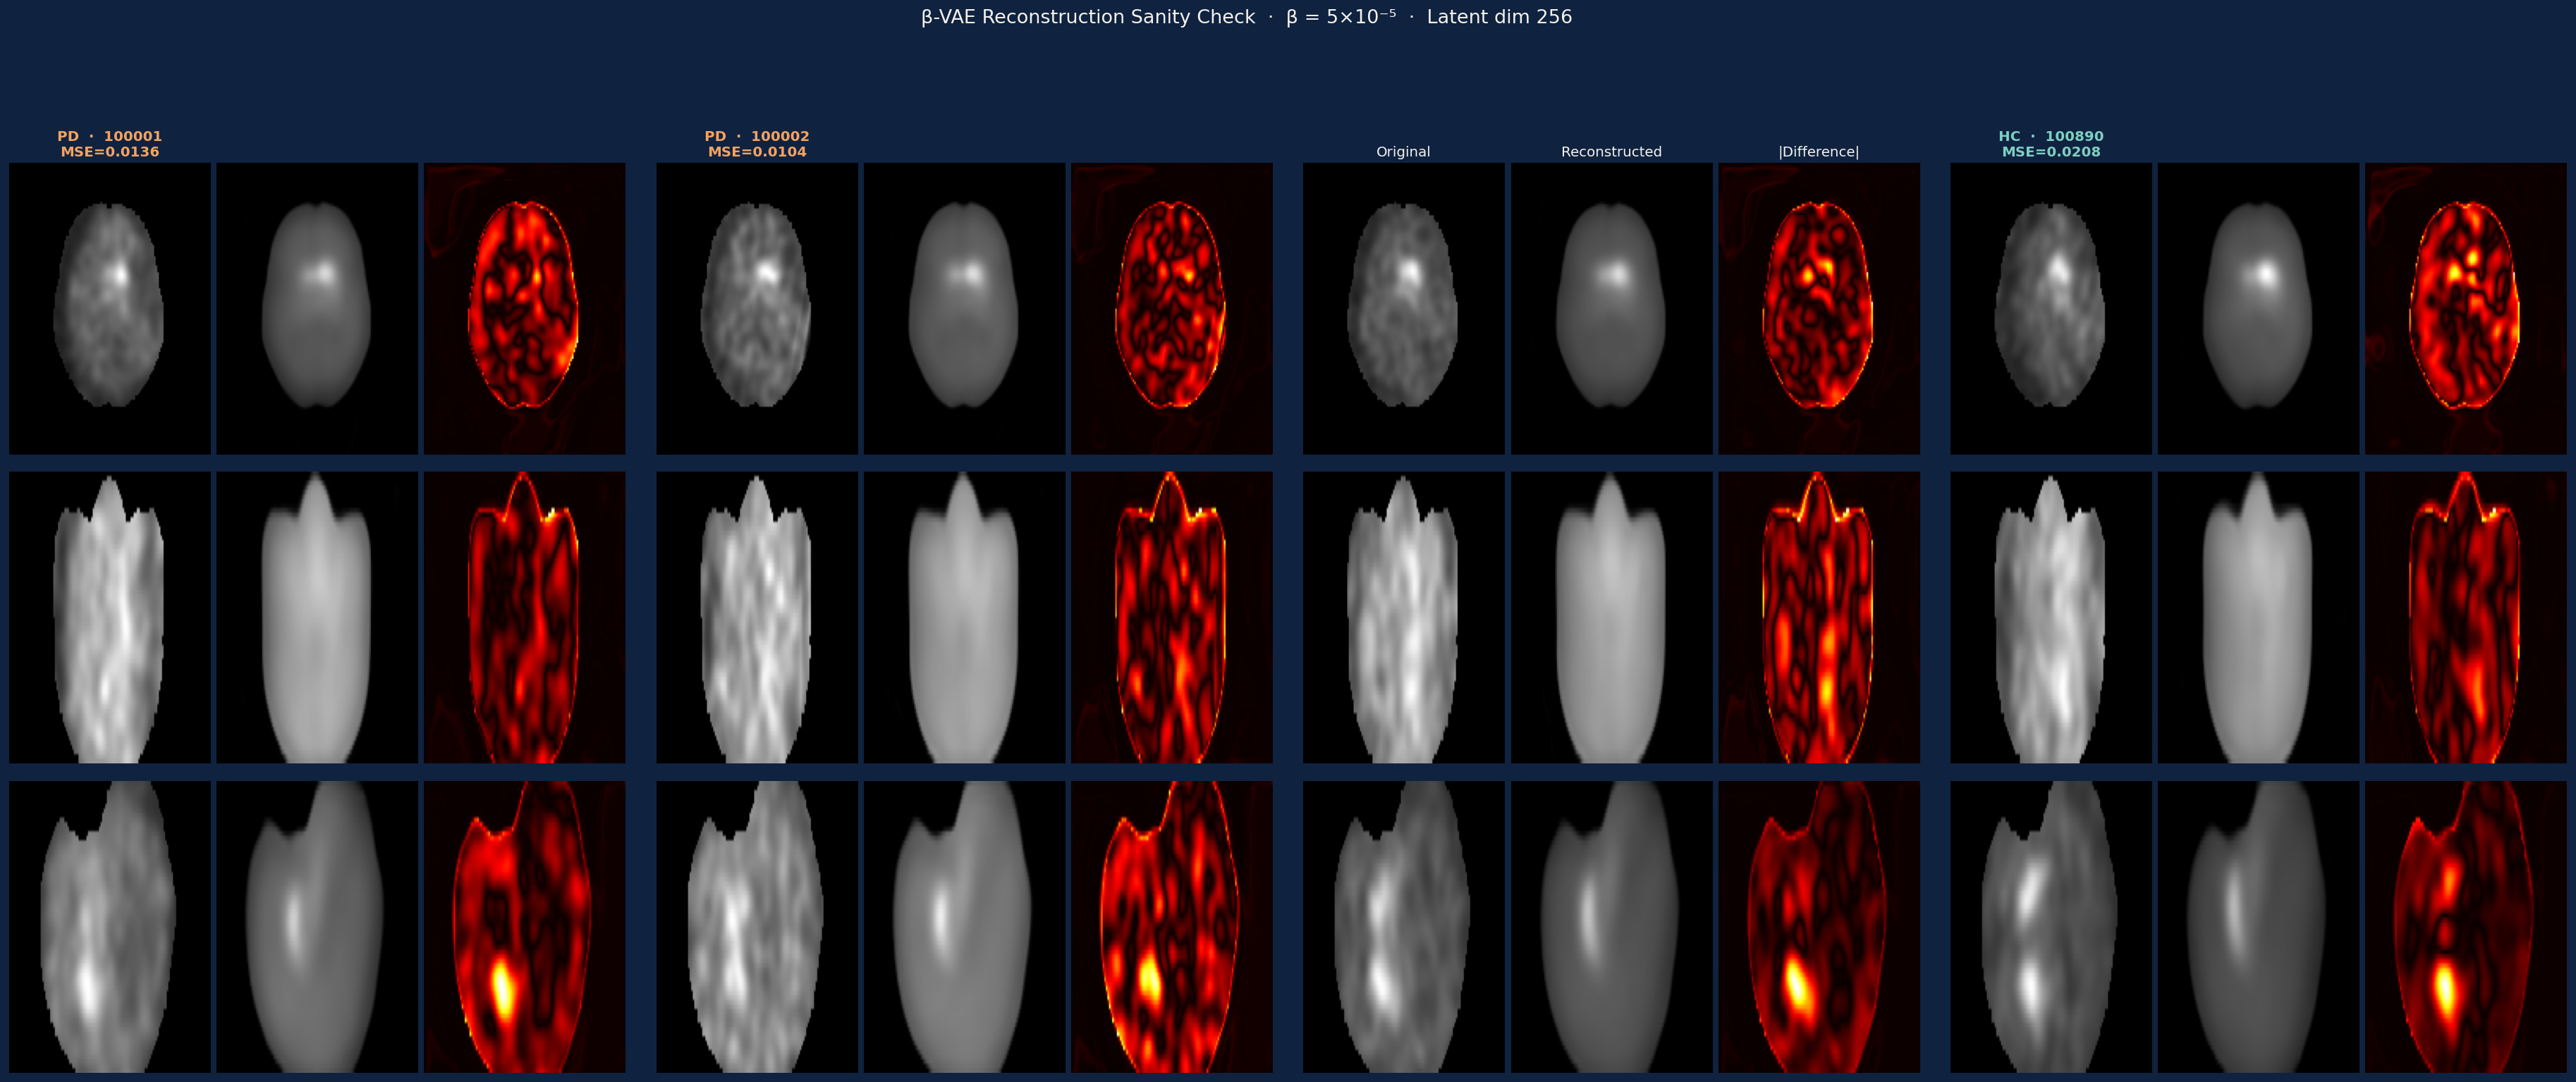

In [19]:
import matplotlib.gridspec as gridspec

# Plot
N = len(results_rc)
fig = plt.figure(figsize=(N * 9, 3 * 3.8 + 1.5), facecolor='#0F2240')
outer = gridspec.GridSpec(1, N, figure=fig, wspace=0.05)

def get_slices(vol):
    return [
        vol[30, :, :],   # axial — striatal level (caudate/putamen)
        vol[:, 64, :],   # coronal
        vol[:, :, 64],   # sagittal
    ]

slice_labels = ['Axial\n(striatum)', 'Coronal', 'Sagittal']

for si, res in enumerate(results_rc):
    inner = gridspec.GridSpecFromSubplotSpec(3, 3, subplot_spec=outer[si],
                                             wspace=0.03, hspace=0.06)
    os_ = get_slices(res['orig'])
    rs_ = get_slices(res['recon'])
    lc  = '#7ECFC0' if res['label'] == 'HC' else '#F4A261'

    for row, (o, r, sl) in enumerate(zip(os_, rs_, slice_labels)):
        diff = np.abs(o - r)
        vmax = max(o.max(), r.max()) + 1e-8
        for col, (img, cmap) in enumerate([(o,'gray'), (r,'gray'), (diff,'hot')]):
            ax = fig.add_subplot(inner[row, col])
            ax.imshow(img, cmap=cmap, vmin=0,
                      vmax=vmax if col < 2 else None, aspect='auto')
            ax.axis('off')
            if col == 0 and row == 0:
                titles = ['Original', 'Reconstructed', '|Difference|']
                ax.set_title(f"{res['label']}  ·  {res['name'][:14]}\nMSE={res['mse']:.4f}",
                             fontsize=11, color=lc, pad=5, fontweight='bold')
            if col == 0:
                ax.set_ylabel(sl, fontsize=9, color='#A8C0C0',
                              rotation=0, labelpad=50, va='center')

# column headers on middle subject
mid = N // 2
for col, title in enumerate(['Original', 'Reconstructed', '|Difference|']):
    ax0 = fig.axes[mid * 9 + col]     # first row axes for middle subject
    ax0.set_title(title, fontsize=11, color='#F5F2EC', pad=5)

fig.suptitle('β-VAE Reconstruction Sanity Check  ·  β = 5×10⁻⁵  ·  Latent dim 256',
             fontsize=15, color='#F5F2EC', y=1.01, fontweight='300')
plt.savefig(os.path.join(FIGURES_DIR, 'reconstruction_sanity_check_v2.png'),
            dpi=130, bbox_inches='tight', facecolor='#0F2240')
plt.close()
print("Saved → results/figures/reconstruction_sanity_check_v2.png")
from IPython.display import Image, display
with open(os.path.join(FIGURES_DIR, 'reconstruction_sanity_check_v2.png'), 'rb') as f:
    display(Image(data=f.read()))

Volume shape: (64, 128, 128)
Axial dim range: 0–63


/var/folders/x_/6yv4myms0vgby9kqty8ns9wh0000gr/T/ipykernel_59734/1042498364.py:35: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return torch.tensor(np.array(d['image'])).float().unsqueeze(0).to(DEVICE)


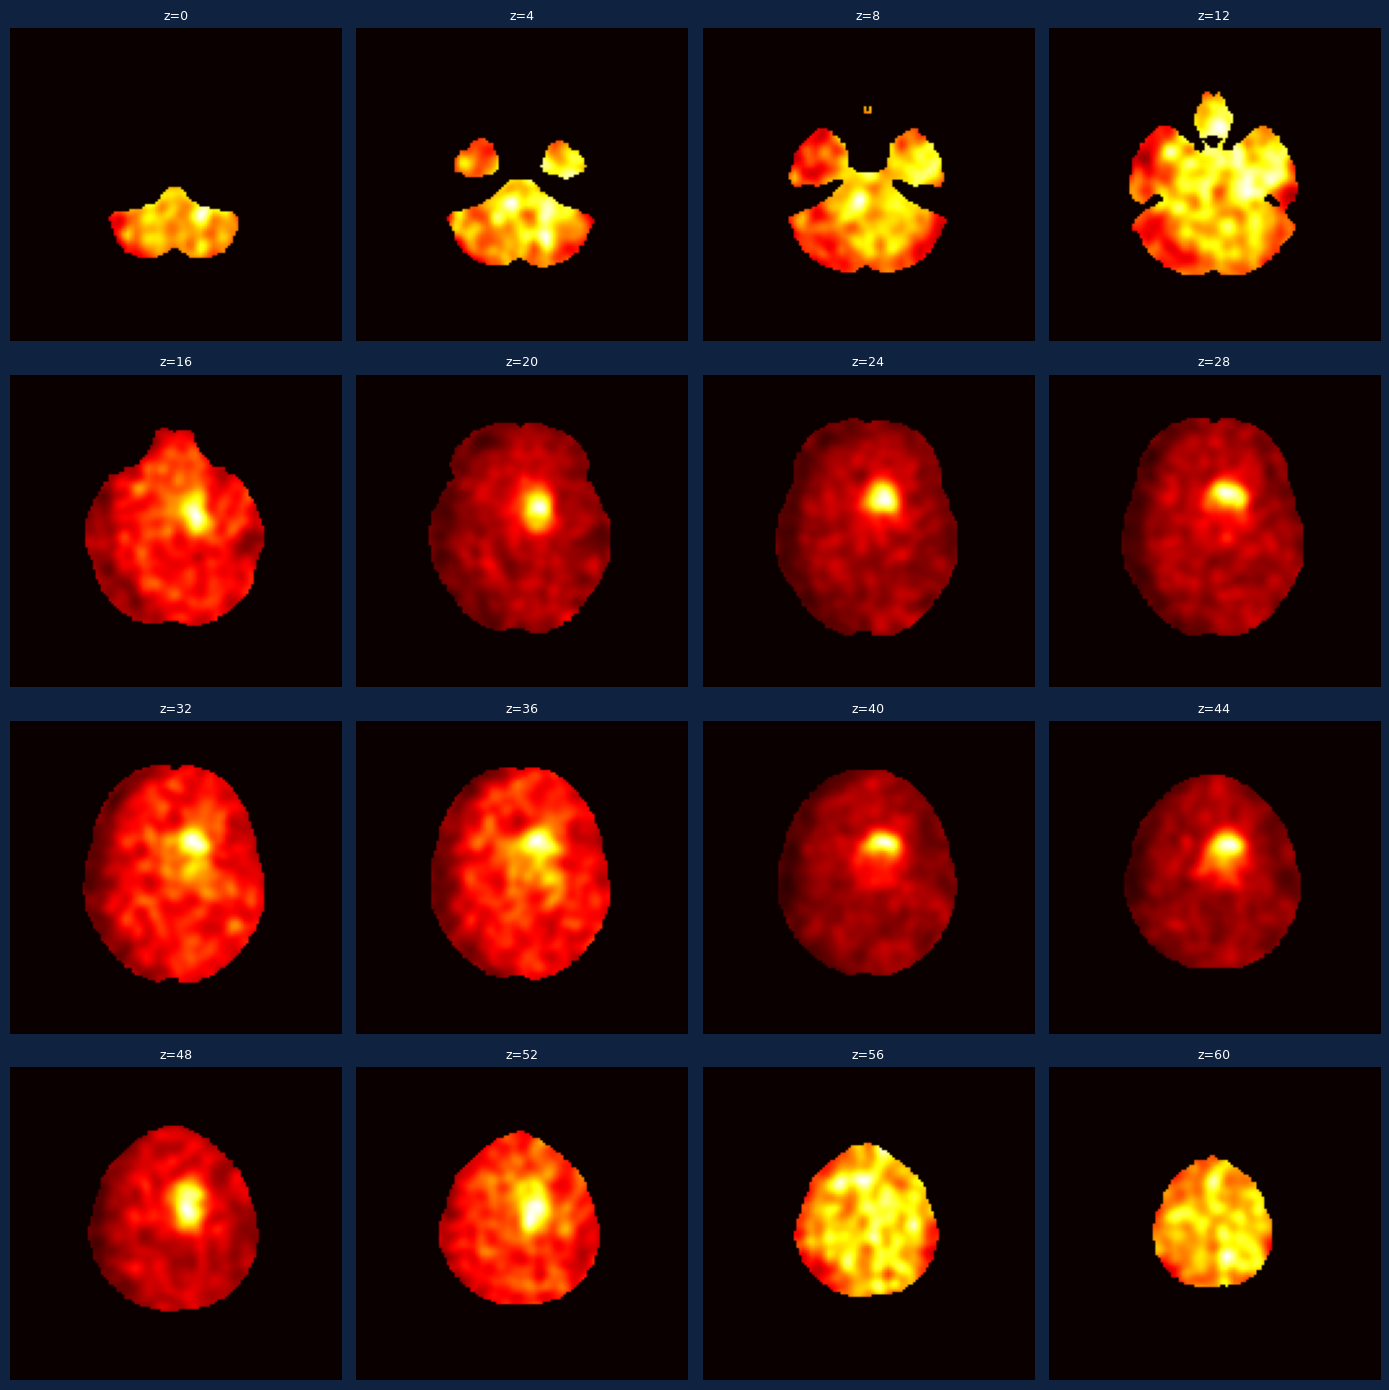

Saved axial_sweep.png


In [20]:
# Find the striatal slice — look for the two bright caudate/putamen spots
import matplotlib.pyplot as plt

# Load one subject
test_tensor = load_and_transform(df_selected.iloc[0]['dcm_path'])
vol = test_tensor[0, 0].cpu().numpy()   # (64, 128, 128) after crop+pad

print(f"Volume shape: {vol.shape}")
print(f"Axial dim range: 0–{vol.shape[0]-1}")

# Plot every 4th axial slice to find where striatum appears
fig, axes = plt.subplots(4, 4, figsize=(14, 14), facecolor='#0F2240')
for i, ax in enumerate(axes.flat):
    sl_idx = i * 4
    ax.imshow(vol[sl_idx, :, :], cmap='hot', aspect='auto')
    ax.set_title(f'z={sl_idx}', color='white', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.savefig('../../results/figures/axial_sweep.png', dpi=100,
            bbox_inches='tight', facecolor='#0F2240')
plt.show()
print("Saved axial_sweep.png")

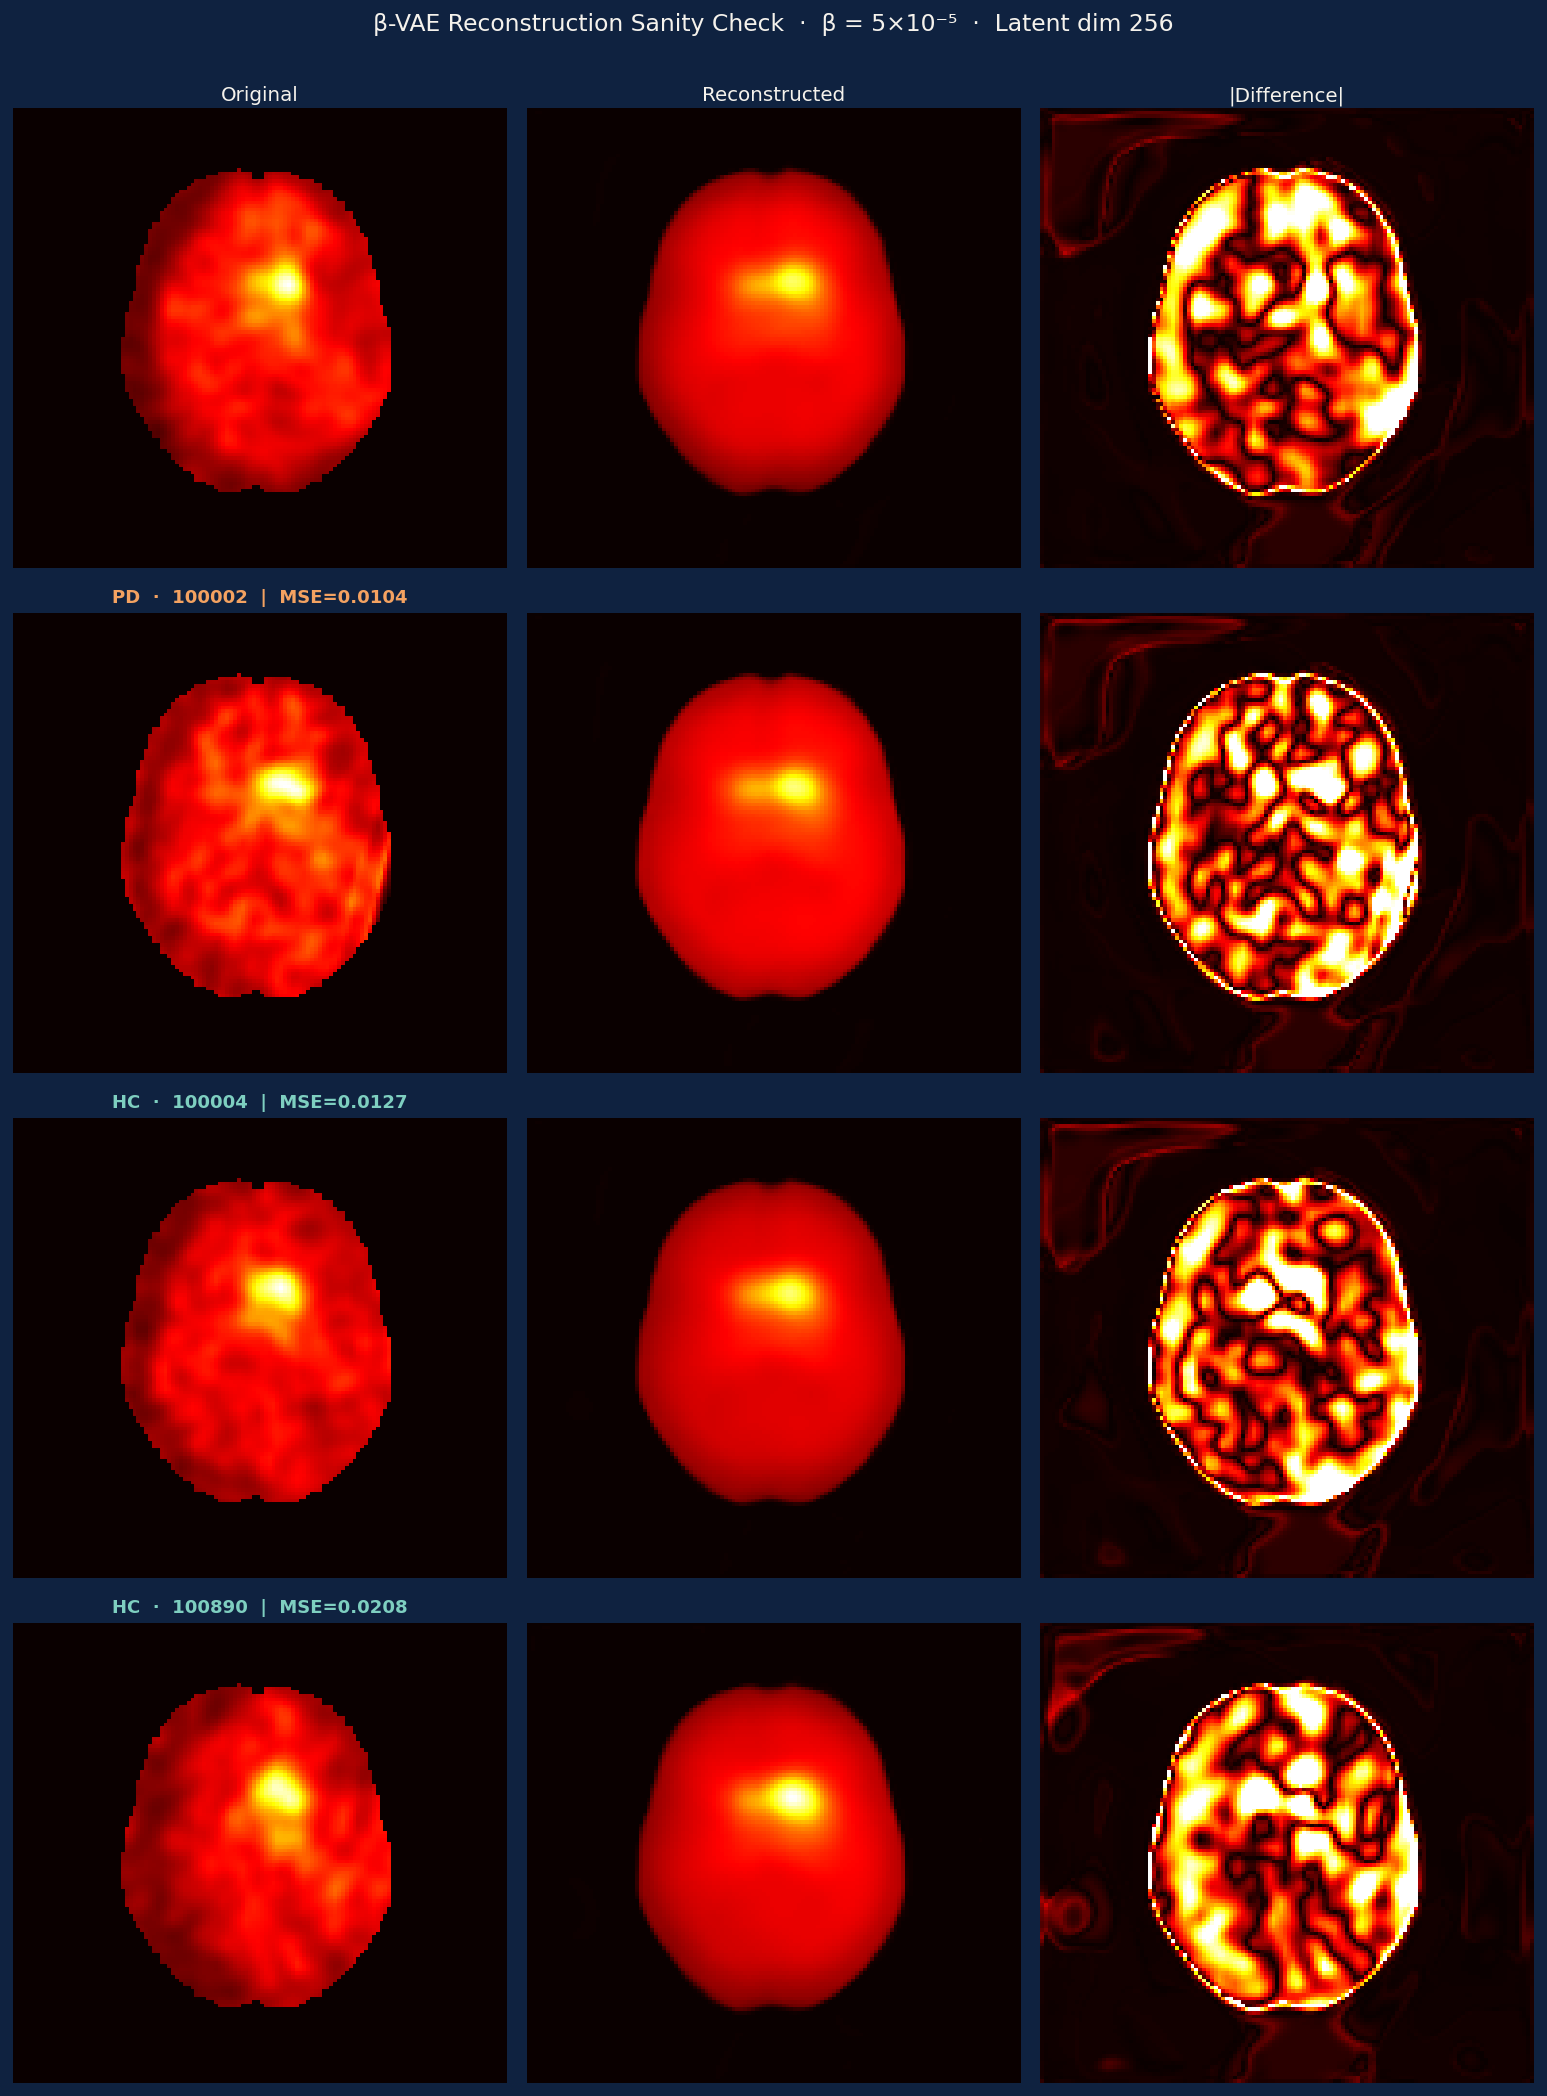

In [21]:
fig, axes = plt.subplots(len(results_rc), 3, figsize=(12, 4 * len(results_rc)),
                         facecolor='#0F2240')
axes = np.array(axes)

for si, res in enumerate(results_rc):
    o = res['orig'][30, :, :]
    r = res['recon'][30, :, :]
    d = np.abs(o - r)
    vmax = max(o.max(), r.max()) + 1e-8
    lc  = '#7ECFC0' if res['label'] == 'HC' else '#F4A261'

    axes[si, 0].imshow(o, cmap='hot', vmin=0, vmax=vmax, aspect='auto')
    axes[si, 0].set_title(f"{res['label']}  ·  {res['name'][:10]}  |  MSE={res['mse']:.4f}",
                          color=lc, fontsize=10, fontweight='bold')
    axes[si, 0].set_ylabel('Axial z=30\n(striatum)', color='#A8C0C0', fontsize=8,
                            rotation=0, labelpad=55, va='center')
    axes[si, 0].axis('off')

    axes[si, 1].imshow(r, cmap='hot', vmin=0, vmax=vmax, aspect='auto')
    axes[si, 1].axis('off')

    axes[si, 2].imshow(d, cmap='hot', vmax=np.percentile(d, 97), aspect='auto')
    axes[si, 2].axis('off')

# Column headers on row 0 only
for col, title in enumerate(['Original', 'Reconstructed', '|Difference|']):
    axes[0, col].set_title(title, color='#F5F2EC', fontsize=11, pad=4)

fig.suptitle('β-VAE Reconstruction Sanity Check  ·  β = 5×10⁻⁵  ·  Latent dim 256',
             fontsize=13, color='#F5F2EC', y=1.005, fontweight='300')

plt.tight_layout()
out_path = os.path.join(FIGURES_DIR, 'reconstruction_sanity_check_v3.png')
plt.savefig(out_path, dpi=130, bbox_inches='tight', facecolor='#0F2240')
plt.close()

from IPython.display import Image, display
with open(out_path, 'rb') as f:
    display(Image(data=f.read()))